<a href="https://www.kaggle.com/code/lucasmoura15/car-classification-dataset?scriptVersionId=352558148" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Dataset: [Car Classification Dataset](https://www.kaggle.com/datasets/stealthtechnologies/car-evaluation-classification)


# Target: Avaliar a aceitabilidade para a compra de um carro


## Features: Preço de Compra, Custo de Manutenção, Número de Portas, Capacidade de Passageiros, Tamanho do Porta-Malas e Nível de Segurança.
### buying, maint, doors, persons, lug_boot, safety


* ##### Colunas: 7
* ##### Linhas: 1728
* ##### Datatype: Ordinais/Categóricos




### 1. Importação de Módulos e Bibliotecas
Nesta célula, carregamos o ecossistema de ferramentas necessárias para o projeto:
* **Manipulação de Dados:** `pandas` e `numpy`.
* **Visualização Gráfica:** `matplotlib.pyplot` e `seaborn`.
* **Machine Learning (Scikit-Learn):**
  - Pré-processamento e divisão dos dados (`OrdinalEncoder`, `StandardScaler`, `train_test_split`).
  - Algoritmo de classificação (`SVC`).
  - Otimização e validação cruzada (`GridSearchCV`).
  - Avaliação de métricas (`accuracy_score`, `classification_report`).

#### Funções Utilizadas:
* `import ... as ...`: Declara e instancia apelidos (*aliases*) para as bibliotecas no ambiente de execução.
* `from ... import ...`: Importa classes e métodos específicos dos submódulos do `sklearn`.
* `OrdinalEncoder`: Classe do módulo `sklearn.preprocessing` utilizada para a conversão automática e padronizada de variáveis categóricas em numéricas, preservando a hierarquia ordinal dos atributos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

### 2. Leitura da Base de Dados e Visualização Inicial
Carregamos o arquivo CSV contendo os registros veiculares e visualizamos as primeiras linhas para conferir os nomes das colunas e a formatação dos dados.

#### Funções Utilizadas:
* `pd.read_csv()`: Lê o arquivo no formato tabular CSV e o converte em um DataFrame do Pandas.
* `df.head()`: Retorna por padrão as 5 primeiras linhas do DataFrame para inspeção visual rápida.

In [2]:
#Caminho para carregamento
caminho_arquivo = '/kaggle/input/datasets/stealthtechnologies/car-evaluation-classification/cars.csv'
df = pd.read_csv(caminho_arquivo)
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


### 3. Análise Exploratória de Dados (EDA) e Distribuição das Variáveis
Executa um diagnóstico detalhado da estrutura do dataset:
1. Exibe a dimensionalidade (linhas $\times$ colunas), consumo de memória e tipos de dados.
2. Gera o resumo estatístico para variáveis categóricas.
3. Plota o gráfico de barras da variável alvo (`class`) para analisar o desbalanceamento de classes.
4. Cria uma grade de subplots com a distribuição individual de cada atributo preditor.

#### Funções Utilizadas:
* `df.shape`: Atributo que informa a contagem de linhas e colunas no formato de tupla `(linhas, colunas)`.
* `df.info()`: Fornece um panorama técnico: tipos de dados (`Dtype`), contagem de valores não-nulos e uso de memória.
* `df.describe()`: Gera estatísticas descritivas (quantidade, valores únicos, valor mais frequente/moda e sua frequência).
* `display()`: Exibe objetos do Pandas em formato visual de tabela HTML interativa no Jupyter.
* `plt.figure()`: Inicializa uma figura gráfica customizando suas dimensões (`figsize`).
* `sns.countplot()`: Plota gráficos de barras com a frequência de ocorrência de cada categoria.
* `plt.title()`, `plt.xlabel()`, `plt.ylabel()`: Definem títulos e rótulos dos eixos cartesianos.
* `ax.patches` / `ax.annotate()`: Itera pelas barras do gráfico para inserir anotações com o valor exato acima de cada uma.
* `plt.subplots()`: Cria uma grade com múltiplas áreas de plotagem (linhas $\times$ colunas) em uma única figura.
* `axes.flatten()`: Converte a matriz de eixos 2D em um vetor unidimensional para facilitar a iteração em laços `for`.
* `plt.tight_layout()`: Ajusta automaticamente os espaçamentos entre subgráficos para evitar sobreposição.
* `plt.show()`: Renderiza a visualização final na tela e limpa o buffer de desenho.

Dimensões da Base
Total de registros: 1728
Total de atributos: 7

Informações de Tipagem e Memória
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Resumo Estatístico


,buying,maint,doors,persons,lug_boot,safety,class
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


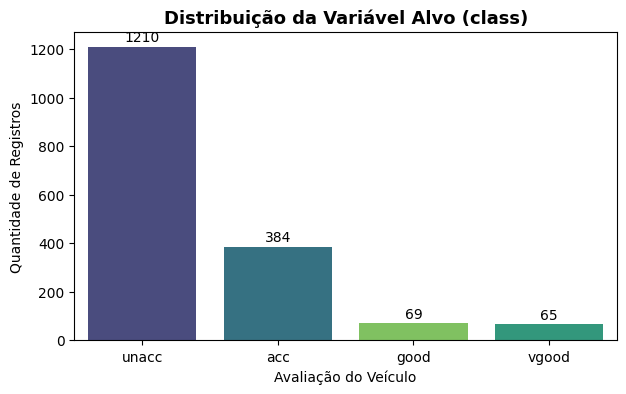

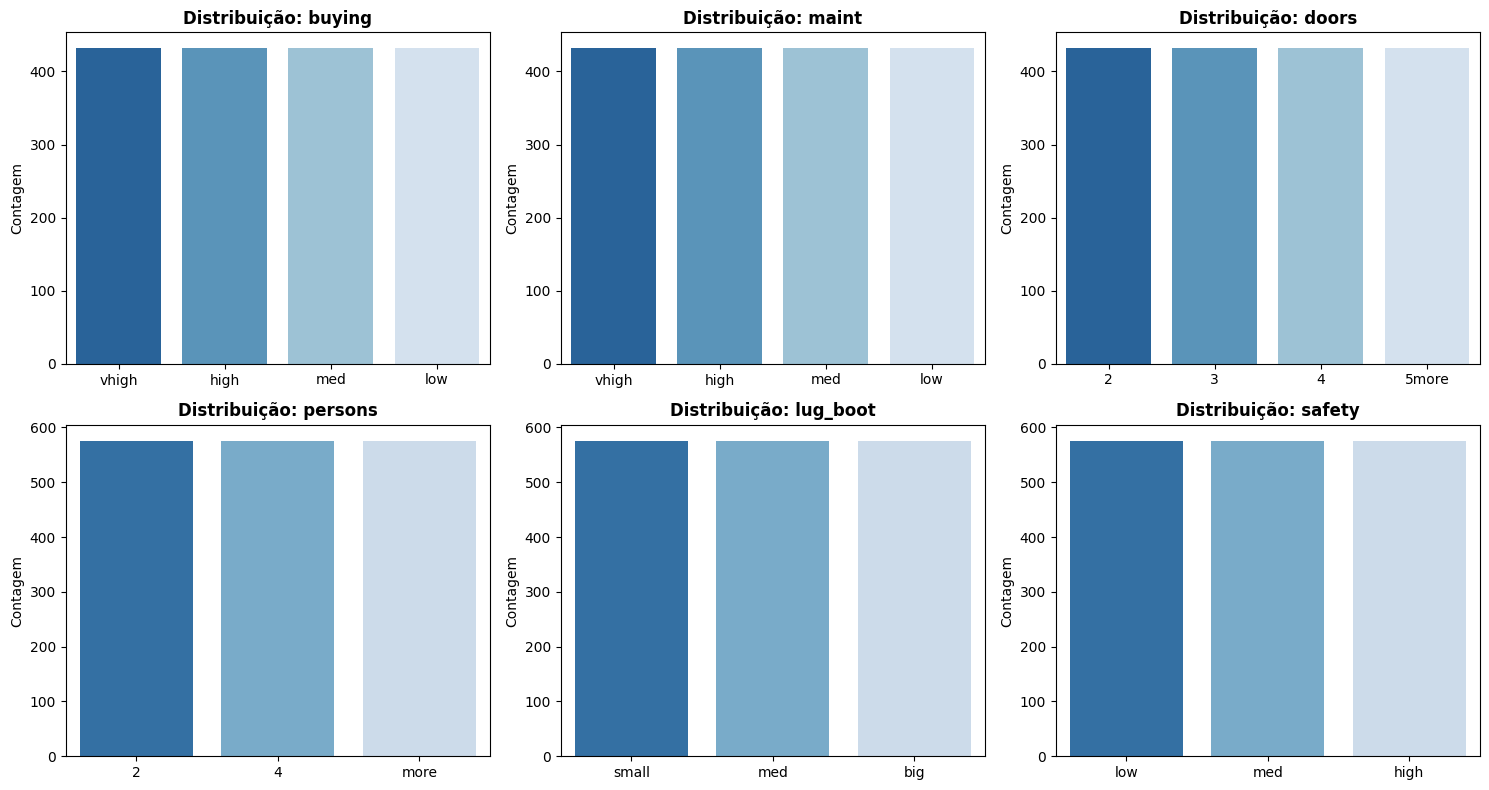

In [3]:
print("Dimensões da Base")
print(f"Total de registros: {df.shape[0]}")
print(f"Total de atributos: {df.shape[1]}\n")

print("Informações de Tipagem e Memória")
df.info()

print("\nResumo Estatístico")
display(df.describe())

#Gráfico da distribuição da variável alvo (class)
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df, 
    x='class', 
    hue='class', 
    order=['unacc', 'acc', 'good', 'vgood'], 
    palette='viridis', 
    legend=False
)
plt.title('Distribuição da Variável Alvo (class)', fontsize=13, fontweight='bold')
plt.xlabel('Avaliação do Veículo')
plt.ylabel('Quantidade de Registros')

#Rótulo de contagem sobre as barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='baseline', fontsize=10, xytext=(0, 4), textcoords='offset points')
plt.show()

#Gráficos das distribuições de cada atributo preditor
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

for ax, col in zip(axes.flatten(), features):
    sns.countplot(data=df, x=col, hue=col, palette='Blues_r', legend=False, ax=ax)
    ax.set_title(f'Distribuição: {col}', fontweight='bold')
    ax.set_ylabel('Contagem')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

### 4. Verificação e Tratamento Defensivo de Valores Ausentes
Audita a integridade dos dados:
1. Faz a contagem de dados ausentes por coluna.
2. Plota um mapa de calor (*heatmap*) para comprovar visualmente a ausência ou presença de nulos.
3. Aplica uma condicional de segurança que remove linhas faltantes caso identificadas.

#### Funções Utilizadas:
* `df.isnull()`: Cria uma máscara booleana indicando `True` para células vazias/NaN e `False` para dados válidos.
* `.sum()`: Soma os valores booleanos por coluna (`True` = 1), retornando a contagem de valores nulos.
* `sns.heatmap()`: Gera uma matriz visual colorida com base nos valores da máscara booleana.
* `df.isnull().values.any()`: Verifica rapidamente se há ao menos um valor nulo em todo o DataFrame.
* `df.dropna()`: Remove as linhas que contêm valores nulos (bloco preventivo).

Quantidade de Nulos por Coluna
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


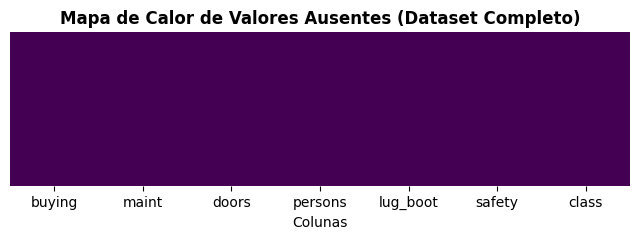


Nenhum valor ausente identificado na base de dados.


In [4]:
print("Quantidade de Nulos por Coluna")
print(df.isnull().sum())

#Gráfico visual comprovando a ausência de dados nulos
plt.figure(figsize=(8, 2))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores Ausentes (Dataset Completo)', fontsize=12, fontweight='bold')
plt.xlabel('Colunas')
plt.show()

#Bloco de segurança defensivo
if df.isnull().values.any():
    linhas_antes = len(df)
    df = df.dropna()
    print(f"\nForam removidas {linhas_antes - len(df)} linhas contendo valores nulos.")
else:
    print("\nNenhum valor ausente identificado na base de dados.")

### 5. Pré-processamento: Codificação Ordinal Automática
Como o algoritmo de SVM requer entradas numéricas, transformamos as variáveis categóricas ordinais em representações numéricas. Para isso, substituímos o antigo mapeamento manual das categorias[cite: 3] por uma abordagem automatizada e profissional:
* Definimos a hierarquia intrínseca e a ordem lógica de cada atributo preditor (por exemplo, `low` $\rightarrow$ `med` $\rightarrow$ `high` $\rightarrow$ `vhigh`)[cite: 1].
* Aplicamos o codificador automático em lote sobre as variáveis preditoras para adequá-las às exigências do modelo matemático[cite: 1, 3].
* Ao final, exibimos as primeiras linhas do DataFrame transformado para conferência visual[cite: 1].

#### Funções Utilizadas:
* `OrdinalEncoder(categories=...)`: Classe do módulo `sklearn.preprocessing` que instancia o codificador, recebendo a ordem hierárquica exata que deve ser respeitada durante a numeração.
* `fit_transform()`: Método que "aprende" as categorias mapeadas e simultaneamente aplica a conversão matemática numérica de forma direta nas colunas selecionadas.
* `display()`: Exibe objetos do Pandas em formato visual de tabela HTML interativa no Jupyter para rápida inspeção dos dados[cite: 1].

In [5]:
#Definindo a ordem hierárquica esperada para cada atributo preditor
categorias = [
    ['low', 'med', 'high', 'vhigh'], # buying
    ['low', 'med', 'high', 'vhigh'], # maint
    ['2', '3', '4', '5more'],        # doors
    ['2', '4', 'more'],              # persons
    ['small', 'med', 'big'],         # lug_boot
    ['low', 'med', 'high']           # safety
]

features = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

# Instanciando e aplicando o OrdinalEncoder de forma automatizada
encoder = OrdinalEncoder(categories=categorias)
df[features] = encoder.fit_transform(df[features])

print("Primeiras Linhas Pós-Encoding Automático")
display(df.head())

Primeiras Linhas Pós-Encoding Automático


,buying,maint,doors,persons,lug_boot,safety,class
0,3.0,3.0,0.0,0.0,0.0,0.0,unacc
1,3.0,3.0,0.0,0.0,0.0,1.0,unacc
2,3.0,3.0,0.0,0.0,0.0,2.0,unacc
3,3.0,3.0,0.0,0.0,1.0,0.0,unacc
4,3.0,3.0,0.0,0.0,1.0,1.0,unacc


### 6. Divisão do Dataset em Conjuntos de Treino e Teste
Nesta etapa, preparamos os dados para o aprendizado supervisionado:
1. Isolamos as variáveis preditoras ($X$) da variável dependente alvo ($y$, correspondente à avaliação do veículo `class`)[cite: 1, 4].
2. Dividimos a base na proporção clássica de 80% para treinamento (1.382 amostras) e 20% para teste (346 amostras)[cite: 4].
3. Aplicamos amostragem estratificada (`stratify=y`) para garantir que a distribuição desbalanceada das quatro classes originais (`unacc`, `acc`, `good`, `vgood`) seja rigorosamente mantida em ambas as partições[cite: 1, 4].
4. Definimos uma semente de aleatoriedade (`random_state=42`) para viabilizar a perfeita reprodutibilidade dos resultados científicos.

#### Funções Utilizadas:
* `df_encoded.drop('class', axis=1)`: Remove a coluna alvo do DataFrame, isolando unicamente a matriz bidimensional de características de entrada ($X$)[cite: 1, 4].
* `train_test_split()`: Função do módulo `sklearn.model_selection` que particiona arrays ou matrizes em subconjuntos aleatórios de treino e teste.
  - `test_size=0.2`: Determina que 20% do volume total de dados seja destinado à avaliação externa de teste[cite: 1, 4].
  - `stratify=y`: Realiza a estratificação com base no vetor alvo, evitando viés de amostragem em classes minoritárias.
  - `random_state=42`: Fixa a semente do gerador de números pseudoaleatórios para garantir a reprodutibilidade da divisão dos dados.
* `print()` / `shape`: Exibe no console a contagem dimensional e a proporção percentual de instâncias alocadas para cada conjunto[cite: 1, 4].v

In [6]:
#Separação entre preditores (X) e variável alvo (y)
X = df.drop('class', axis=1)
y = df['class']

#Divisão em Treino (80%) e Teste (20%) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("--- Divisão dos Dados ---")
print(f"Instâncias de Treino: {X_train.shape[0]} ({X_train.shape[0]/len(df):.0%})")
print(f"Instâncias de Teste:  {X_test.shape[0]} ({X_test.shape[0]/len(df):.0%})\n")

--- Divisão dos Dados ---
Instâncias de Treino: 1382 (80%)
Instâncias de Teste:  346 (20%)



### 7. Padronização de Escala dos Atributos (StandardScaler)
O classificador SVM (*Support Vector Machine*) fundamenta-se no cálculo de distâncias euclidianas e margens geométricas ótimas no hiperplano[cite: 1, 4]. Por essa razão, a escala das variáveis exerce influência direta sobre a convergência do algoritmo[cite: 1, 4]:
1. Ajustamos a escala das variáveis para uma distribuição z-score com média zero ($\mu = 0$) e variância unitária ($\sigma^2 = 1$)[cite: 1, 4].
2. Calculamos a média e o desvio padrão **exclusivamente sobre o conjunto de treino** e reaplicamos esses parâmetros sobre os dados de teste[cite: 1, 4]. Essa prática metodológica impede o vazamento de dados (*data leakage*), assegurando que o conjunto de teste represente fielmente dados inéditos de produção[cite: 1, 4].

#### Funções Utilizadas:
* `StandardScaler()`: Construtor da classe de padronização do `sklearn.preprocessing`, responsável por centralizar e reescalonar as variáveis com base na fórmula $Z = \frac{x - \mu}{\sigma}$[cite: 1, 4].
* `scaler.fit_transform()`: Estima os parâmetros estatísticos (média e desvio padrão) com base no conjunto de treino e aplica imediatamente o reescalonamento sobre ele[cite: 1, 4].
* `scaler.transform()`: Padroniza o conjunto de teste utilizando estritamente os parâmetros ($\mu$ e $\sigma$) obtidos a partir do conjunto de treinamento, preservando o isolamento do teste[cite: 1, 4].

In [7]:
#Padronização dos atributos (Fundamental para o cálculo de margem do SVM)
scaler = StandardScaler()

#O fit_transform é aplicado unicamente no treino; o teste recebe apenas transform
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Padronização com StandardScaler concluída com sucesso.")

Padronização com StandardScaler concluída com sucesso.


### 8. Otimização de Hiperparâmetros via Validação Cruzada (GridSearchCV)
Realiza uma busca em grade exaustiva para determinar a melhor combinação de hiperparâmetros do classificador SVM:
* Parâmetro de regularização `C`: `[0.1, 1, 10, 100]`
* Coeficiente de curvatura `gamma`: `['scale', 'auto', 0.01, 0.1, 1]`
* Função de núcleo `kernel`: `['rbf', 'linear', 'poly']`
A validação cruzada estratificada em 5 folds é utilizada para garantir generalização estatística.

#### Funções Utilizadas:
* `StratifiedKFold(n_splits=5, ...)`: Configura a validação cruzada dividindo o conjunto em 5 dobras balanceadas.
* `SVC()`: Construtor do classificador de Máquinas de Vetores de Suporte (Support Vector Classifier).
* `GridSearchCV()`: Executa o treinamento e teste de todas as 60 combinações possíveis de parâmetros ao longo das 5 dobras (300 fits ao todo).
* `grid_svm.fit()`: Executa o processo de treinamento e seleção automática da melhor configuração.
* `grid_svm.best_params_`: Atributo que armazena a combinação de hiperparâmetros que atingiu a maior acurácia média.
* `grid_svm.best_score_`: Atributo com a média de acurácia obtida pela melhor configuração durante a validação cruzada.

In [8]:
from sklearn.model_selection import StratifiedKFold

#Definição do grid de hiperparâmetros para teste
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear', 'poly']
}

#Configuração do GridSearchCV com 5 folds estratificados
grid_svm = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Iniciando busca de hiperparâmetros")
grid_svm.fit(X_train_scaled, y_train)

print("\nResultados do GridSearchCV")
print(f"Melhores hiperparâmetros encontrados: {grid_svm.best_params_}")
print(f"Acurácia média na Validação Cruzada: {grid_svm.best_score_:.4f}")

Iniciando busca de hiperparâmetros
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Resultados do GridSearchCV
Melhores hiperparâmetros encontrados: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Acurácia média na Validação Cruzada: 0.9834


### 9. Predição e Avaliação de Desempenho no Conjunto de Teste
O modelo com a melhor combinação de hiperparâmetros realiza previsões sobre o conjunto de teste (dados nunca vistos pelo algoritmo durante o treino). São calculadas a acurácia global e as métricas detalhadas por classe: Precisão, Revocação (*Recall*) e F1-Score.

#### Funções Utilizadas:
* `best_svm.predict()`: Gera as predições de classes para as amostras de teste padronizadas.
* `accuracy_score()`: Calcula a proporção de previsões corretas sobre o total de amostras avaliadas.
* `classification_report()`: Gera um relatório completo com métricas de classificação (`precision`, `recall`, `f1-score` e `support`) para cada categoria individual e suas médias globais (macro e ponderada).

In [9]:
#Recupera o melhor modelo treinado
best_svm = grid_svm.best_estimator_

#Predições no conjunto de teste
y_pred = best_svm.predict(X_test_scaled)

#Cálculo da acurácia e relatório completo
acc = accuracy_score(y_test, y_pred)
print(f"Acurácia no Conjunto de Teste: {acc:.4%}\n")

print("Relatório de Classificação (Classification Report)")
print(classification_report(y_test, y_pred))

Acurácia no Conjunto de Teste: 99.1329%

Relatório de Classificação (Classification Report)
              precision    recall  f1-score   support

         acc       0.97      0.99      0.98        77
        good       1.00      1.00      1.00        14
       unacc       1.00      0.99      0.99       242
       vgood       1.00      1.00      1.00        13

    accuracy                           0.99       346
   macro avg       0.99      0.99      0.99       346
weighted avg       0.99      0.99      0.99       346



### 10. Diagnóstico Visual: Matriz de Confusão e Comparação de Kernels
1. Constrói a **Matriz de Confusão** para identificar visualmente onde ocorreram os acertos e eventuais erros entre as 4 classes do problema.
2. Analisa os resultados de todas as combinações avaliadas pelo `GridSearchCV` e plota um gráfico de barras comparando o teto de acurácia atingido por cada tipo de `kernel` (`rbf`, `poly`, `linear`).

#### Funções Utilizadas:
* `confusion_matrix()`: Computa a matriz de contagem relacionando rótulos reais (`y_test`) e previsões (`y_pred`).
* `pd.DataFrame(grid_svm.cv_results_)`: Transforma os resultados brutos da validação cruzada em um DataFrame para facilitar manipulação e agrupamentos.
* `groupby()` / `max()`: Agrupa os registros por tipo de kernel e extrai a pontuação máxima de acurácia de cada um.
* `sns.barplot()`: Plota gráficos de barras verticais para comparação direta das categorias de kernel.

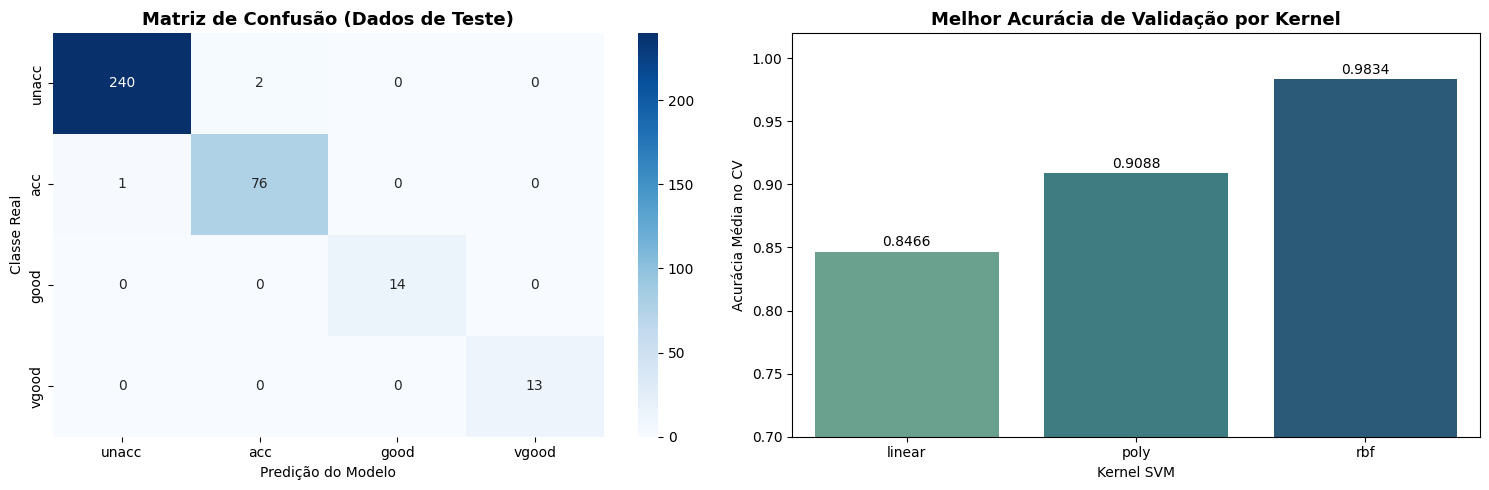

In [10]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels_order = ['unacc', 'acc', 'good', 'vgood']

#Matriz de Confusão
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', 
    xticklabels=labels_order, yticklabels=labels_order, 
    ax=axes[0]
)
axes[0].set_title('Matriz de Confusão (Dados de Teste)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predição do Modelo')
axes[0].set_ylabel('Classe Real')

#Desempenho Médio do GridSearch por Tipo de Kernel
cv_results_df = pd.DataFrame(grid_svm.cv_results_)
kernel_perf = cv_results_df.groupby('param_kernel')['mean_test_score'].max().reset_index()

sns.barplot(
    data=kernel_perf, 
    x='param_kernel', 
    y='mean_test_score', 
    hue='param_kernel', 
    palette='crest', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Melhor Acurácia de Validação por Kernel', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kernel SVM')
axes[1].set_ylabel('Acurácia Média no CV')
axes[1].set_ylim(0.7, 1.02)

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:.4f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='baseline', fontsize=10, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()